 # Task-2 (Week-5)

**Date** :- (02-11-26)

**Dataset** :- 'Admission_Prediction.csv'

**Objective** :- Analyze feature importance in ensemble models to identify the most influential applicant attributes affecting admission decisions, supporting transparent and fair selection processes

In [1]:
# Import Library

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    StratifiedKFold, cross_validate, cross_val_predict,
    GridSearchCV
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, balanced_accuracy_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)

In [2]:
# Load Dataset

df = pd.read_csv("Admission_Prediction.csv")
print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (1000, 17)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Year,Application_Date,University_Name,region,Admission Status,Duration_Months,Dropout_Event,Dropout-free survival
0,104,317,104,2,4.5,4.0,8.47,0,0.57,2022,03-01-2022,Indian Institute of Technology Bombay,West,Rejected,36,0,0.536473
1,170,311,99,2,2.5,3.0,7.98,0,0.65,2022,09-01-2022,Indian Institute of Technology Delhi,North,Rejected,18,1,0.973000
2,138,316,100,2,1.5,3.0,8.16,1,0.71,2022,12-01-2022,Indian Institute of Technology Delhi,North,Rejected,33,0,0.597989
3,147,315,105,3,2.0,2.5,8.48,0,0.75,2022,13-01-2022,Indian Institute of Technology Delhi,North,Accepted,33,0,0.597989
4,117,299,102,3,4.0,3.5,8.62,0,0.56,2022,14-01-2022,Indian Institute of Technology Delhi,North,Rejected,28,1,0.734170


Columns:
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Year', 'Application_Date', 'University_Name', 'region', 'Admission Status', 'Duration_Months', 'Dropout_Event', 'Dropout-free survival']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Serial No.             1000 non-null   int64  
 1   GRE Score              1000 non-null   int64  
 2   TOEFL Score            1000 non-null   int64  
 3   University Rating      1000 non-null   int64  
 4   SOP                    1000 non-null   float64
 5   LOR                    1000 non-null   float64
 6   CGPA                   1000 non-null   float64
 7   Research               1000 non-null   int64  
 8   Chance of Admit        1000 non-null   float64
 9   Year                   1000 non-null   int64  
 10  A

None

,Missing values
Serial No.,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,0
Chance of Admit,0
Year,0


\nTarget distribution:


,Count
Admission Status,
Rejected,565
Accepted,435


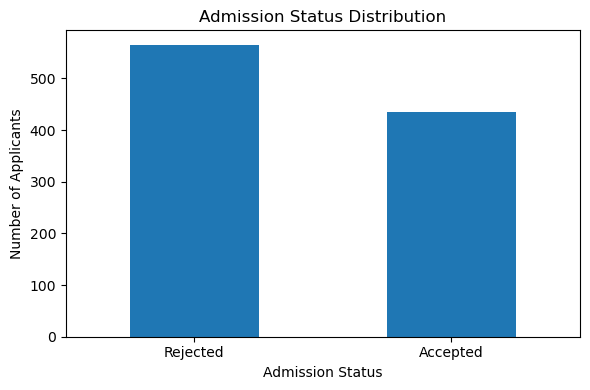

In [3]:
# Inspect data and target distribution

print("Columns:")
print(df.columns.tolist())

display(df.info())
display(df.isnull().sum().to_frame("Missing values"))

TARGET = "Admission Status"
if TARGET not in df.columns:
    raise KeyError(f"Target column '{TARGET}' is missing.")

print("\\nTarget distribution:")
display(df[TARGET].value_counts(dropna=False).to_frame("Count"))

ax = df[TARGET].value_counts().plot(kind="bar", figsize=(6, 4))
ax.set_title("Admission Status Distribution")
ax.set_xlabel("Admission Status")
ax.set_ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
# Prepare features and target

# Remove rows without a known target
data = df.dropna(subset=[TARGET]).copy()

# Explicitly exclude ID, target, possible leakage, and post-admission survival fields.
excluded_columns = [
    "Serial No.",
    TARGET,
    "Chance of Admit",
    "Duration_Months",
    "Dropout_Event",
    "Dropout-free survival"
]

# Application_Date is converted into a numeric application year/month feature
# only if it can be parsed. Original text date is not fed directly to the model.
if "Application_Date" in data.columns:
    app_dates = pd.to_datetime(data["Application_Date"], errors="coerce", dayfirst=True)
    data["Application_Month"] = app_dates.dt.month
    # Year already exists in this dataset; avoid duplicating it.
    excluded_columns.append("Application_Date")

feature_columns = [c for c in data.columns if c not in excluded_columns]
X = data[feature_columns].copy()
y = data[TARGET].astype(str).str.strip()

# Drop rows where target is blank-like
valid_target = y.ne("") & y.ne("nan")
X = X.loc[valid_target].copy()
y = y.loc[valid_target].copy()

print("Feature columns:", feature_columns)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", sorted(y.unique()))
display(y.value_counts().to_frame("Count"))

Feature columns: ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Year', 'University_Name', 'region', 'Application_Month']
X shape: (1000, 11)
y shape: (1000,)
Classes: ['Accepted', 'Rejected']


,Count
Admission Status,
Rejected,565
Accepted,435


In [5]:
# Build preprocessing and Random Forest pipeline

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        n_jobs=-1
    ))
])

print("Preprocessing and Random Forest pipeline created successfully.")

Preprocessing and Random Forest pipeline created successfully.


In [6]:
# Stratified 5-Fold Cross-Validation

class_counts = y.value_counts()
n_splits = min(5, int(class_counts.min()))

if n_splits < 2:
    raise ValueError(
        "Each target class must contain at least two examples for stratified cross-validation."
    )

skf = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted"
}

# ROC AUC is calculated only when this is a binary classification task.
if y.nunique() == 2:
    scoring["roc_auc"] = "roc_auc"

cv_results = cross_validate(
    estimator=rf_model,
    X=X,
    y=y,
    cv=skf,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise"
)

cv_summary = pd.DataFrame({
    metric.replace("test_", "").replace("_", " ").title(): [
        np.mean(cv_results[metric]),
        np.std(cv_results[metric]),
        np.min(cv_results[metric]),
        np.max(cv_results[metric])
    ]
    for metric in cv_results if metric.startswith("test_")
}, index=["Mean", "Std Dev", "Minimum", "Maximum"]).T

display(cv_summary.round(4))

,Mean,Std Dev,Minimum,Maximum
Accuracy,0.6720,0.0238,0.6500,0.7150
Balanced Accuracy,0.6513,0.0215,0.6321,0.6909
Precision Weighted,0.6727,0.0286,0.6463,0.7239
Recall Weighted,0.6720,0.0238,0.6500,0.7150
F1 Weighted,0.6621,0.0219,0.6427,0.7027
Roc Auc,0.7391,0.0186,0.7150,0.7712


,Fold,Accuracy,Balanced Accuracy,Weighted F1
0,1,0.650,0.6321,0.6427
1,2,0.650,0.6321,0.6427
2,3,0.715,0.6909,0.7027
3,4,0.670,0.6524,0.6631
4,5,0.675,0.6489,0.6594


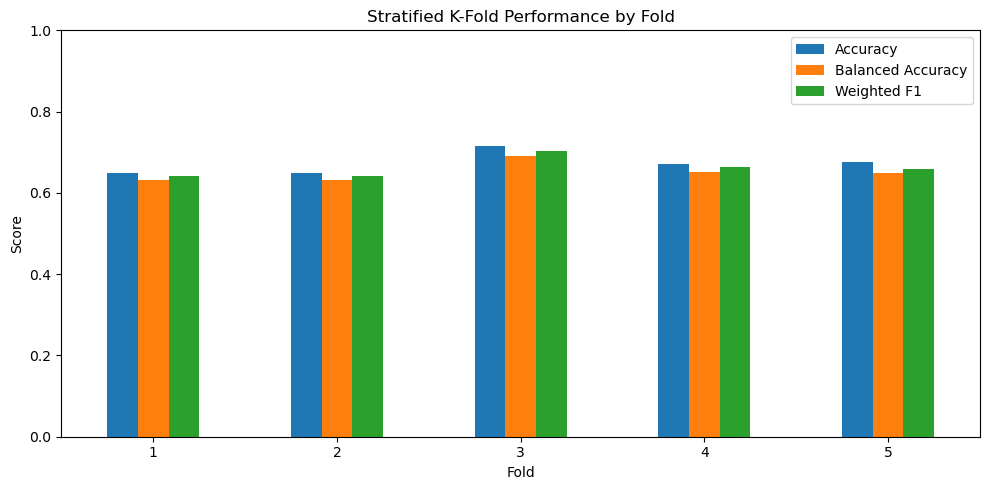

In [7]:
# Visualize fold-wise cross-validation scores

fold_scores = pd.DataFrame({
    "Fold": np.arange(1, n_splits + 1),
    "Accuracy": cv_results["test_accuracy"],
    "Balanced Accuracy": cv_results["test_balanced_accuracy"],
    "Weighted F1": cv_results["test_f1_weighted"]
})

display(fold_scores.round(4))

fold_scores.set_index("Fold").plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1)
)
plt.title("Stratified K-Fold Performance by Fold")
plt.ylabel("Score")
plt.xlabel("Fold")
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

In [8]:
# Nested Cross-Validation
# Inner loop for hyperparameter selection
inner_splits = min(3, int(class_counts.min()))
if inner_splits < 2:
    raise ValueError("Not enough examples per class for inner stratified CV.")

inner_cv = StratifiedKFold(
    n_splits=inner_splits,
    shuffle=True,
)

outer_cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

param_grid = {
    "classifier__n_estimators": [150, 200, 300],
    "classifier__max_depth": [None, 10, 15],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

inner_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=inner_cv,
    n_jobs=1,
    refit=True
)

nested_results = cross_validate(
    estimator=inner_search,
    X=X,
    y=y,
    cv=outer_cv,
    scoring=scoring,
    return_estimator=True,
    n_jobs=1,  # Avoid nested parallel oversubscription
    error_score="raise"
)

nested_summary = pd.DataFrame({
    metric.replace("test_", "").replace("_", " ").title(): [
        np.mean(nested_results[metric]),
        np.std(nested_results[metric]),
        np.min(nested_results[metric]),
        np.max(nested_results[metric])
    ]
    for metric in nested_results if metric.startswith("test_")
}, index=["Mean", "Std Dev", "Minimum", "Maximum"]).T

print("Nested CV performance (outer folds):")
display(nested_summary.round(4))

Nested CV performance (outer folds):


,Mean,Std Dev,Minimum,Maximum
Accuracy,0.6520,0.0368,0.6000,0.7150
Balanced Accuracy,0.6352,0.0362,0.5918,0.6989
Precision Weighted,0.6510,0.0372,0.5990,0.7149
Recall Weighted,0.6520,0.0368,0.6000,0.7150
F1 Weighted,0.6443,0.0369,0.5994,0.7095
Roc Auc,0.7373,0.0320,0.6999,0.7932


In [9]:
# Review best hyperparameters selected inside each outer fold

best_parameters = []
for fold_number, fitted_search in enumerate(nested_results["estimator"], start=1):
    best_parameters.append({
        "Outer Fold": fold_number,
        **fitted_search.best_params_,
        "Inner Best F1": fitted_search.best_score_
    })

best_params_df = pd.DataFrame(best_parameters)
display(best_params_df)

,Outer Fold,classifier__max_depth,classifier__min_samples_leaf,classifier__min_samples_split,classifier__n_estimators,Inner Best F1
0,1,15.0,1,5,200,0.680452
1,2,10.0,1,2,300,0.659804
2,3,10.0,1,5,300,0.675499
3,4,NaN,2,5,150,0.667121
4,5,10.0,2,2,200,0.659102


In [10]:
# Compare standard CV and nested CV

comparison_metrics = ["accuracy", "balanced_accuracy", "precision_weighted",
                      "recall_weighted", "f1_weighted"]
if y.nunique() == 2:
    comparison_metrics.append("roc_auc")

comparison_rows = []
for metric in comparison_metrics:
    comparison_rows.append({
        "Metric": metric.replace("_", " ").title(),
        "Stratified K-Fold Mean": np.mean(cv_results[f"test_{metric}"]),
        "Nested CV Mean": np.mean(nested_results[f"test_{metric}"]),
        "Stratified K-Fold Std": np.std(cv_results[f"test_{metric}"]),
        "Nested CV Std": np.std(nested_results[f"test_{metric}"])
    })

comparison_df = pd.DataFrame(comparison_rows).set_index("Metric")
display(comparison_df.round(4))

,Stratified K-Fold Mean,Nested CV Mean,Stratified K-Fold Std,Nested CV Std
Metric,,,,
Accuracy,0.6720,0.6520,0.0238,0.0368
Balanced Accuracy,0.6513,0.6352,0.0215,0.0362
Precision Weighted,0.6727,0.6510,0.0286,0.0372
Recall Weighted,0.6720,0.6520,0.0238,0.0368
F1 Weighted,0.6621,0.6443,0.0219,0.0369
Roc Auc,0.7391,0.7373,0.0186,0.0320


              precision    recall  f1-score   support

    Accepted       0.66      0.46      0.54       435
    Rejected       0.66      0.82      0.73       565

    accuracy                           0.66      1000
   macro avg       0.66      0.64      0.64      1000
weighted avg       0.66      0.66      0.65      1000



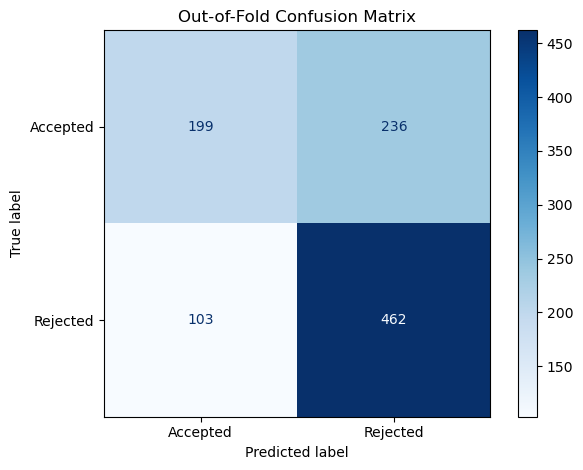

In [11]:
# Out-of-fold predictions and confusion matrix

oof_predictions = cross_val_predict(
    estimator=rf_model,
    X=X,
    y=y,
    cv=skf,
    method="predict",
    n_jobs=-1
)

print(classification_report(y, oof_predictions, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(y, oof_predictions, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", values_format="d")
plt.title("Out-of-Fold Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
# Train final tuned model on all available data

final_inner_cv = StratifiedKFold(
    n_splits=inner_splits,
    shuffle=True,
)

final_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=final_inner_cv,
    n_jobs=1,
    refit=True
)

final_search.fit(X, y)
best_model = final_search.best_estimator_

print("Final best parameters:")
print(final_search.best_params_)
print("Final inner-CV best weighted F1:", round(final_search.best_score_, 4))
print("Final model trained on all available rows.")

Final best parameters:
{'classifier__max_depth': 15, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 150}
Final inner-CV best weighted F1: 0.6682
Final model trained on all available rows.


,Feature,Importance
5,num__CGPA,0.138544
0,num__GRE Score,0.119769
1,num__TOEFL Score,0.112435
3,num__SOP,0.090525
7,num__Year,0.089309
4,num__LOR,0.079120
2,num__University Rating,0.055288
8,num__Application_Month,0.050939
6,num__Research,0.037287
63,cat__region_West,0.010906


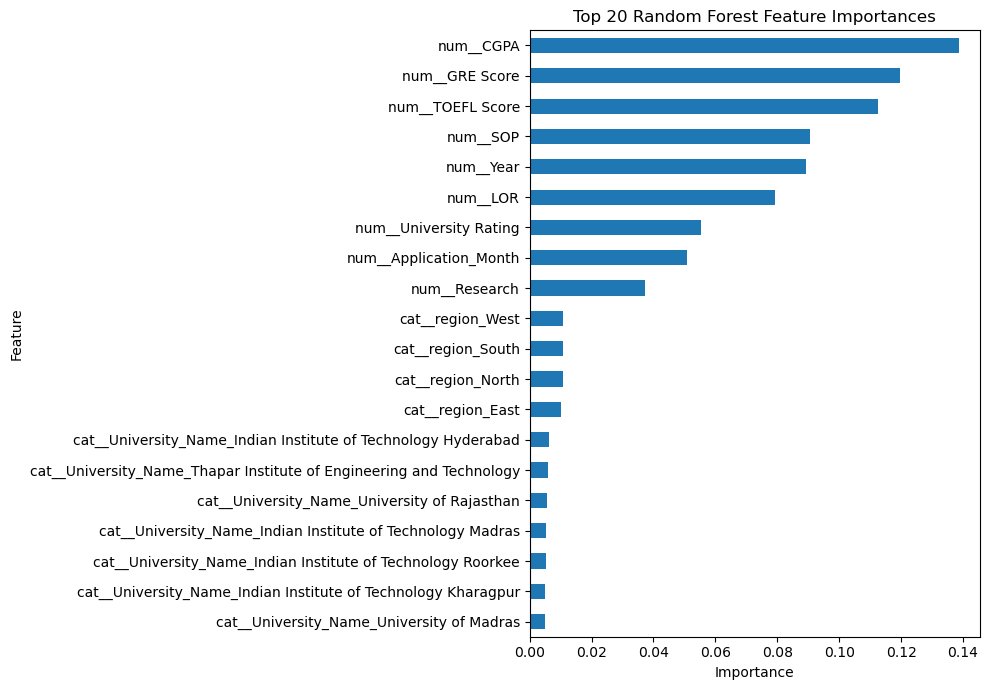

In [13]:
# Feature importance (final fitted Random Forest)

fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_classifier = best_model.named_steps["classifier"]

try:
    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = fitted_classifier.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)

    display(importance_df.head(20))

    importance_df.head(20).sort_values("Importance").plot(
        x="Feature", y="Importance", kind="barh", figsize=(10, 7), legend=False
    )
    plt.title("Top 20 Random Forest Feature Importances")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
except Exception as exc:
    print("Could not extract feature names:", exc)

In [14]:
# Save results and trained model

import joblib

pd.DataFrame(cv_results).drop(columns=["estimator"], errors="ignore").to_csv(
    "stratified_kfold_results.csv", index=False
)
pd.DataFrame(nested_results).drop(columns=["estimator"], errors="ignore").to_csv(
    "nested_cv_results.csv", index=False
)
comparison_df.to_csv("cv_comparison.csv")
best_params_df.to_csv("nested_cv_best_parameters.csv", index=False)
joblib.dump(best_model, "admission_random_forest_model.joblib")

print("All cross-validation results and the final model have been saved.")

All cross-validation results and the final model have been saved.
